# 5.2 - Cài đặt DBSCAN với Python
**Họ và tên:** Thái Anh Lạc  
**MSSV:** 089206000860  
**Mã lớp học phần:** 012012204103  
**Môn học:** Khai thác dữ liệu (Data Mining)

In [81]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
import time

# Tạo dữ liệu hình 2 vầng trăng khuyết kèm nhiễu
X, _ = make_moons(n_samples=300, noise=0.08, random_state=42)

In [82]:
# Thuật toán DBSCAN tự cài đặt
def dbscan_scratch(X, eps=0.2, min_samples=5):
    labels = np.full(len(X), -1)  # Mặc định tất cả điểm là Nhiễu (-1)
    cluster_id = 0
    
    for i in range(len(X)):
        if labels[i] != -1:  # Đã gán vào cụm thì bỏ qua
            continue
            
        # Tìm các điểm lân cận trong bán kính eps
        neighbors = np.where(np.linalg.norm(X - X[i], axis=1) <= eps)[0].tolist()
        
        # Nếu là Điểm lõi (>= min_samples) -> Loang mở rộng cụm
        if len(neighbors) >= min_samples:
            labels[i] = cluster_id
            for n in neighbors:
                if labels[n] == -1:  # Gán các điểm lân cận vào cụm
                    labels[n] = cluster_id
                    sub = np.where(np.linalg.norm(X - X[n], axis=1) <= eps)[0]
                    if len(sub) >= min_samples:  # Nếu lân cận cũng là lõi -> loang tiếp
                        neighbors.extend([x for x in sub if x not in neighbors])
            cluster_id += 1
            
    return labels

# Đo thời gian DBSCAN tự viết
t0 = time.time()
labels_scratch = dbscan_scratch(X, eps=0.2, min_samples=5)
time_scratch = time.time() - t0

In [83]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import adjusted_rand_score

# Đo thời gian DBSCAN Scikit-Learn
t0 = time.time()
labels_sklearn = DBSCAN(eps=0.2, min_samples=5).fit_predict(X)
time_sklearn = time.time() - t0

# In bảng đối chiếu kết quả & thời gian
print("1. Độ trùng khớp (ARI):", adjusted_rand_score(labels_scratch, labels_sklearn))
print(f"2. Số cụm:    Tự viết = {len(set(labels_scratch)-{-1})}, Sklearn = {len(set(labels_sklearn)-{-1})}")
print(f"3. Số nhiễu:  Tự viết = {list(labels_scratch).count(-1)}, Sklearn = {list(labels_sklearn).count(-1)}")
print(f"4. Thời gian: Tự viết = {time_scratch*1000:.2f} ms | Sklearn = {time_sklearn*1000:.2f} ms")

1. Độ trùng khớp (ARI): 1.0
2. Số cụm:    Tự viết = 2, Sklearn = 2
3. Số nhiễu:  Tự viết = 0, Sklearn = 0
4. Thời gian: Tự viết = 10.24 ms | Sklearn = 1.00 ms


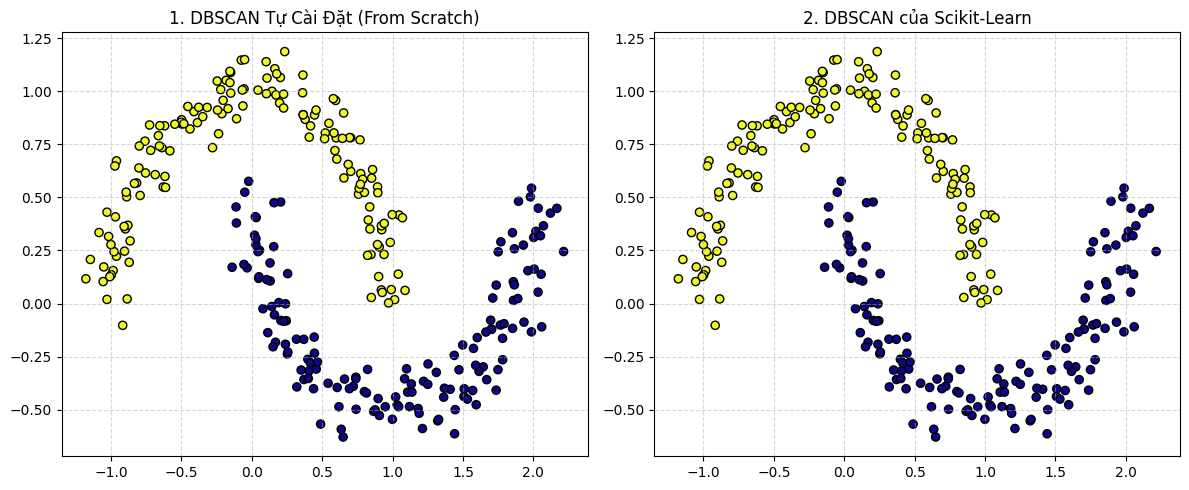

In [84]:
# Vẽ 2 biểu đồ so sánh
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Biểu đồ tự viết
ax1.scatter(X[:, 0], X[:, 1], c=labels_scratch, cmap='plasma', s=35, edgecolor='k')
ax1.set_title("1. DBSCAN Tự Cài Đặt (From Scratch)")
ax1.grid(True, linestyle='--', alpha=0.5)

# Biểu đồ Sklearn
ax2.scatter(X[:, 0], X[:, 1], c=labels_sklearn, cmap='plasma', s=35, edgecolor='k')
ax2.set_title("2. DBSCAN của Scikit-Learn")
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()